# BAB IV — Klasifikasi Software Inventory GLPI

**Metodologi:** CRISP-DM  
**Algoritma:** TF-IDF + Logistic Regression dan Linear SVM  
**Lingkungan:** Visual Studio Code (Jupyter Notebook / Python 3)

**Rancangan data:** 12.318 data mentah → 9.256 software unik → **7.404 training + 1.852 testing (80:20)**.

> **Penting:** Karena belum semua software mempunyai label IT, notebook membuat **label sementara (proxy)** menggunakan GLPI Dictionary dan kebijakan default INCLUDE. Nilai accuracy dan confusion matrix seluruh 1.852 data menunjukkan **kesesuaian terhadap proxy label**, **bukan akurasi terhadap ground truth IT**. Hasil evaluasi khusus label IT ditampilkan terpisah ketika file label tersedia. Tidak ada aturan yang diubah pada GLPI produksi.

## 4.1 Business Understanding

Penelitian bertujuan membuat rekomendasi **INCLUDE** (masuk laporan aplikasi utama IT) atau **EXCLUDE_CANDIDATE** (perlu ditinjau untuk tidak ditampilkan di laporan utama). Kata EXCLUDE bukan perintah menghapus software dari GLPI.

## 4.2 Data Understanding

### KODE 01 — Import Library dan Folder Proyek

**Tujuan:** Menyiapkan library untuk pengolahan data dan klasifikasi.  
**Output:** Folder hasil tersedia.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
CANDIDATES = [Path.cwd(), Path.cwd().parent]
BASE = next((folder for folder in CANDIDATES if (folder / 'SoftwareDataset.csv').exists()), None)
if BASE is None:
    raise FileNotFoundError('Place SoftwareDataset.csv in the VS Code project folder.')

OUTPUT = BASE / 'hasil_bab4'
OUTPUT.mkdir(exist_ok=True)
print('Project folder:', BASE)

Project folder: c:\Users\magang.tiga\Documents\CODE_GLPI


### KODE 02 — Membaca Dataset

**Tujuan:** Memuat seluruh data GLPI sebelum dibersihkan.  
**Output:** Jumlah baris serta contoh data.

In [2]:
raw = pd.read_csv(BASE / 'SoftwareDataset.csv', dtype=str).fillna('')
print('Raw records:', len(raw))
display(raw.head())

Raw records: 12318


,software_id,software_name,manufacturer,software_category,entity_id
0,72,,Microsoft,License,0
1,"36,057",,,,0
2,"36,006",(244) hafid.algofiri@cemindo.com,mail.cemindo.com,none,0
3,"35,990",{01ef7197-4deb-4997-a10c-3627ffe1b4c8},,application,0
4,"36,039",{05F81C27-62A5-4A0C-8519-60CB66CF87C6},,application,0


### KODE 03 — Memeriksa Struktur dan Nilai Kosong

**Tujuan:** Mengetahui kolom dan kelengkapan data.  
**Output:** Tabel jumlah nilai kosong.

In [3]:
print('Dataset shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.eq('').sum().to_frame('missing_count'))

Dataset shape: (12318, 5)
Columns: ['software_id', 'software_name', 'manufacturer', 'software_category', 'entity_id']


,missing_count
software_id,0
software_name,2
manufacturer,681
software_category,3465
entity_id,0


### KODE 04 — Melihat Duplikasi Nama Software

**Tujuan:** Mengetahui banyaknya nama software yang berulang.  
**Output:** Jumlah nama kosong dan duplikat.

In [4]:
name_check = raw['software_name'].str.strip().str.lower()
print('Empty names:', name_check.eq('').sum())
print('Unique non-empty names:', name_check[name_check.ne('')].nunique())
print('Duplicate name records:', name_check[name_check.ne('')].duplicated().sum())

Empty names: 2
Unique non-empty names: 9322
Duplicate name records: 2994


## 4.2.1 Exploratory Data Analysis (EDA)

### KODE 05 — Distribusi Kategori Software

**Tujuan:** Menampilkan kategori software paling banyak.  
**Output:** Tabel dan grafik kategori.

,total
software_category,
application,4108
Unknown,3465
system_component,2234
store,1299
system,590
License,258
developer,240
none,58
libraries,38


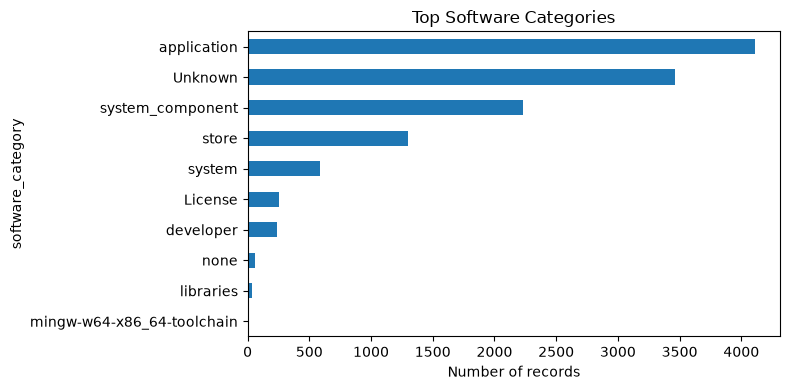

In [5]:
category_counts = raw['software_category'].replace('', 'Unknown').value_counts().head(10)
display(category_counts.to_frame('total'))
category_counts.sort_values().plot.barh(figsize=(8, 4), title='Top Software Categories')
plt.xlabel('Number of records')
plt.tight_layout()
plt.show()

### KODE 06 — Distribusi Manufacturer

**Tujuan:** Menampilkan manufacturer software paling banyak.  
**Output:** Tabel dan grafik manufacturer.

,total
manufacturer,
Microsoft Corporation,2079
Unknown,686
Siemens AG,503
AUTODESK,497
Python Software Foundation,458
Microsoft,422
Corel Corporation,402
Microsoft Platform Extensions,329
Adobe Systems Incorporated,245


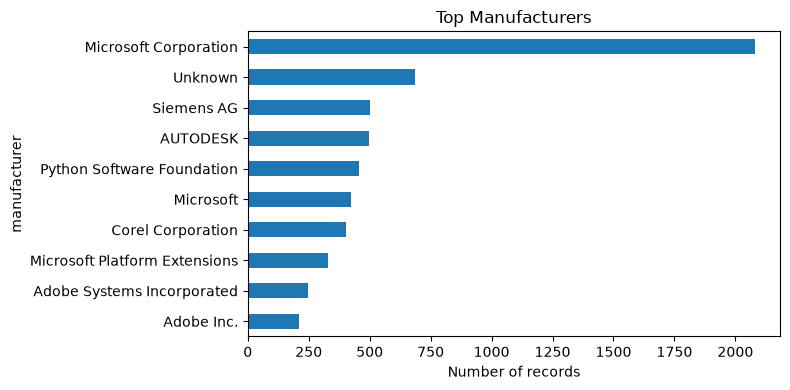

In [6]:
manufacturer_counts = raw['manufacturer'].replace('', 'Unknown').value_counts().head(10)
display(manufacturer_counts.to_frame('total'))
manufacturer_counts.sort_values().plot.barh(figsize=(8, 4), title='Top Manufacturers')
plt.xlabel('Number of records')
plt.tight_layout()
plt.show()

### KODE 07 — Analisis Panjang Nama Software

**Tujuan:** Melihat karakteristik teks nama software.  
**Output:** Statistik dan histogram panjang nama.

,name_length
count,12316.0
mean,28.5
std,16.7
min,2.0
25%,16.0
50%,26.0
75%,37.0
max,125.0


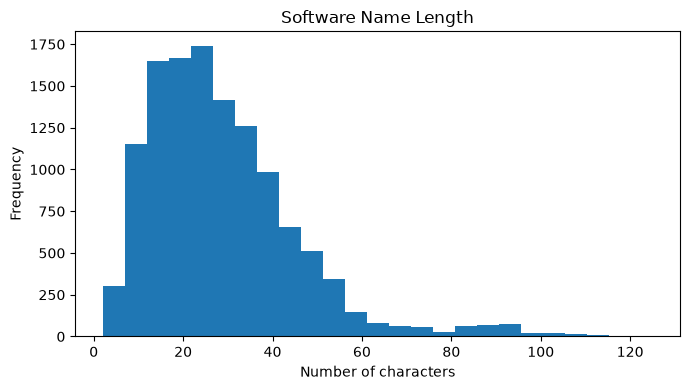

In [7]:
name_lengths = raw.loc[raw['software_name'].str.strip().ne(''), 'software_name'].str.len()
display(name_lengths.describe().round(1).to_frame('name_length'))
name_lengths.plot.hist(bins=25, figsize=(7, 4), title='Software Name Length')
plt.xlabel('Number of characters')
plt.tight_layout()
plt.show()

## 4.3 Data Preparation

### KODE 08 — Normalisasi dan Pembersihan Data

**Tujuan:** Membuat satu baris untuk setiap nama software unik.  
**Output:** Katalog software bersih.

In [8]:
def normalize_name(value):
    return re.sub(r'\s+', ' ', str(value).strip().lower())

cleaned = raw.copy()
cleaned['name_key'] = cleaned['software_name'].map(normalize_name)
cleaned = cleaned[cleaned['name_key'].ne('')].copy()
cleaned['metadata_count'] = (cleaned[['manufacturer', 'software_category']] != '').sum(axis=1)
cleaned = cleaned.sort_values('metadata_count', ascending=False)

catalog = cleaned.drop_duplicates('name_key').drop(columns='metadata_count').reset_index(drop=True)
catalog['text'] = (catalog['software_name'] + ' ' + catalog['manufacturer'] + ' ' +
                   catalog['software_category']).str.strip()
print('Clean software names:', len(catalog))
display(catalog.head())

Clean software names: 9256


,software_id,software_name,manufacturer,software_category,entity_id,name_key,text
0,"35,993",한국어 로컬 경험 팩,Microsoft Corporation,store,0,한국어 로컬 경험 팩,한국어 로컬 경험 팩 Microsoft Corporation store
1,"36,006",(244) hafid.algofiri@cemindo.com,mail.cemindo.com,none,0,(244) hafid.algofiri@cemindo.com,(244) hafid.algofiri@cemindo.com mail.cemindo....
2,"26,784",인증서 로밍 클라이언트 오픈뱅킹 (1.04),"BTWorks, Inc.",application,0,인증서 로밍 클라이언트 오픈뱅킹 (1.04),"인증서 로밍 클라이언트 오픈뱅킹 (1.04) BTWorks, Inc. applica..."
3,"35,926",解压软件,"Wuhan Net Power Technology Co., Ltd",store,0,解压软件,"解压软件 Wuhan Net Power Technology Co., Ltd store"
4,"35,941",看图软件,"Wuhan Net Power Technology Co., Ltd",store,0,看图软件,"看图软件 Wuhan Net Power Technology Co., Ltd store"


### KODE 09 — Menyimpan Dataset Bersih

**Tujuan:** Menyimpan data hasil preprocessing.  
**Output:** File CSV katalog unik.

In [9]:
catalog.to_csv(OUTPUT / '01_clean_software_catalog.csv', index=False)
print('Saved:', OUTPUT / '01_clean_software_catalog.csv')

Saved: c:\Users\magang.tiga\Documents\CODE_GLPI\hasil_bab4\01_clean_software_catalog.csv


### KODE 10 — Membaca GLPI Software Dictionary

**Tujuan:** Memuat aturan pengecualian yang sudah tersedia.  
**Output:** Jumlah aturan dan contoh isinya.

In [11]:
rules = pd.read_csv(BASE / 'Rule_Software_Dictionary.csv', dtype=str).fillna('')
ignore_rules = rules[
    rules['action'].str.strip().str.lower().eq('ignore import') &
    rules['active_in_user_paste'].str.strip().str.lower().eq('yes')
].copy()
print('Total dictionary rules:', len(rules))
print('Active ignore rules:', len(ignore_rules))
display(ignore_rules.head())

Total dictionary rules: 67
Active ignore rules: 65


,dictionary,rule_id,criteria_field,operator,pattern,action,active_in_user_paste,risiko_rule,catatan_audit,cocok_di_sampel_500,cocok_software_keep_ai,cocok_software_review_ai,cocok_software_ignore_ai
0,Software,210,Software,is,PrimoPDF,Ignore import,Yes,SEDANG,Aplikasi PDF utama dapat penting untuk audit l...,0.0,0.0,0.0,0.0
1,Software,211,Software,starting with,KB,Ignore import,Yes,PERLU UJI,Periksa bahwa pattern hanya menarget entri tek...,0.0,0.0,0.0,0.0
2,Software,231,Software,starting with,Microsoft Family,Ignore import,Yes,PERLU UJI,Periksa bahwa pattern hanya menarget entri tek...,0.0,0.0,0.0,0.0
3,Software,232,Software,contains,Update for Microsoft,Ignore import,Yes,PERLU UJI,Periksa bahwa pattern hanya menarget entri tek...,0.0,0.0,0.0,0.0
4,Software,233,Software,contains,Visual C,Ignore import,Yes,TINGGI,Visual C/VC runtime sering dibutuhkan; jangan ...,0.0,0.0,0.0,0.0


### KODE 11 — Mencocokkan Software dengan Dictionary

**Tujuan:** Menandai nama software yang cocok dengan aturan Ignore import.  
**Output:** Jumlah cocok dan ID aturan.

In [12]:
catalog['dictionary_rule_id'] = ''

field_map = {
    'software': 'software_name',
    'publisher': 'manufacturer',
    'category from inventory tool': 'software_category'
}

for _, rule in ignore_rules.iterrows():
    field = field_map.get(rule['criteria_field'].strip().lower())
    pattern = rule['pattern'].strip().lower()
    operator = rule['operator'].strip().lower()
    if not field or not pattern:
        continue

    values = catalog[field].str.lower()
    if operator == 'is':
        matched = values.eq(pattern)
    elif operator == 'starting with':
        matched = values.str.startswith(pattern)
    elif operator == 'contains':
        matched = values.str.contains(re.escape(pattern), regex=True)
    else:
        continue

    first_match = matched & catalog['dictionary_rule_id'].eq('')
    catalog.loc[first_match, 'dictionary_rule_id'] = rule['rule_id']

catalog['dictionary_hit'] = catalog['dictionary_rule_id'].ne('')
print('Matches:', int(catalog['dictionary_hit'].sum()))
print('No match:', int((~catalog['dictionary_hit']).sum()))

Matches: 2385
No match: 6871


### KODE 12 — Memuat Label Referensi IT (Opsional)

**Tujuan:** Membaca 200 atau 1.000 label IT ketika file tersedia.  
**Output:** Jumlah label yang cocok dengan katalog.

In [43]:
label_candidates = [
    'IT_Validation_200.xlsx', 'IT_Validation_200.csv',
    'Label_IT_200.xlsx', 'Label_IT_200.csv'
]
label_file = next((BASE / name for name in label_candidates if (BASE / name).exists()), None)
it_labels = pd.DataFrame(columns=['name_key', 'it_label'])

if label_file is not None:
    source = pd.read_excel(label_file, dtype=str) if label_file.suffix == '.xlsx' else pd.read_csv(label_file, dtype=str)
    source = source.fillna('')
    name_column = next((c for c in ['software_name', 'name_key', 'Software', 'Software Name'] if c in source), None)
    label_column = next((c for c in ['label_final_it', 'label_it', 'label', 'Label'] if c in source), None)
    if not name_column or not label_column:
        raise ValueError('Label file needs software_name and label_final_it (or label).')

    value_map = {
        '0': 0, '0.0': 0, 'include': 0,
        '1': 1, '1.0': 1, 'exclude': 1,
        'exclude_candidate': 1, 'exclude candidate': 1
    }
    it_labels = pd.DataFrame({
        'name_key': source[name_column].map(normalize_name),
        'it_label': source[label_column].astype(str).str.strip().str.lower().map(value_map)
    }).dropna(subset=['it_label'])
    it_labels = it_labels[it_labels['name_key'].ne('')]
    conflict = it_labels.groupby('name_key')['it_label'].nunique()
    if (conflict > 1).any():
        raise ValueError('Some software names have conflicting IT labels. Check the label file.')
    it_labels = it_labels.drop_duplicates('name_key')
    it_labels['it_label'] = it_labels['it_label'].astype(int)

catalog = catalog.merge(it_labels, on='name_key', how='left')
print('Label file:', label_file.name if label_file else 'Not available yet')
print('Matched IT labels:', int(catalog['it_label'].notna().sum()))
print('IT label counts:', catalog['it_label'].value_counts().to_dict()) 

Label file: IT_Validation_200.xlsx
Matched IT labels: 200
IT label counts: {0.0: 114, 1.0: 86}


### KODE 13 — Membuat Label Sementara untuk Seluruh Software

**Tujuan:** Menyiapkan proxy label supaya semua data dapat dibagi dan diuji.  
**Output:** 9.256 label kerja dengan sumber label.

In [44]:
# These are provisional study labels, NOT independently verified ground truth.
catalog['proxy_label'] = np.where(catalog['dictionary_hit'], 1, 0)
catalog['label_source'] = np.where(catalog['dictionary_hit'],
                                   'DICTIONARY_RULE', 'DEFAULT_INCLUDE_PROXY')

known = catalog['it_label'].notna()
catalog.loc[known, 'proxy_label'] = catalog.loc[known, 'it_label'].astype(int)
catalog.loc[known, 'label_source'] = 'IT_REFERENCE'
catalog['proxy_label'] = catalog['proxy_label'].astype(int)

print('Proxy label counts:', catalog['proxy_label'].value_counts().to_dict())
display(catalog['label_source'].value_counts().to_frame('total'))
print('WARNING: Proxy labels are not verified ground truth.')

Proxy label counts: {0: 6837, 1: 2419}


,total
label_source,
DEFAULT_INCLUDE_PROXY,6723
DICTIONARY_RULE,2333
IT_REFERENCE,200


### KODE 14 — Train-Test Split Seluruh 9.256 Software

**Tujuan:** Membagi semua software bersih menjadi training dan testing (80:20).  
**Output:** 7.404 training dan 1.852 testing.

In [45]:
train_data, test_data = train_test_split(
    catalog, test_size=0.20, random_state=RANDOM_STATE,
    stratify=catalog['proxy_label']
)
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print('Training:', len(train_data))
print('Testing:', len(test_data))
print('Total:', len(train_data) + len(test_data))
print('IT labels in testing:', int(test_data['it_label'].notna().sum()))
assert set(train_data['name_key']).isdisjoint(set(test_data['name_key']))

Training: 7404
Testing: 1852
Total: 9256
IT labels in testing: 38


### KODE 15 — Menyimpan Data Training dan Testing

**Tujuan:** Mendokumentasikan pembagian data penelitian.  
**Output:** Dua file CSV hasil split.

In [46]:
train_data.to_csv(OUTPUT / '02_training_data.csv', index=False)
test_data.to_csv(OUTPUT / '03_testing_data.csv', index=False)
print('Training and testing files saved.')

Training and testing files saved.


## 4.4 Modeling

Kedua model memakai **data training yang sama**. Label training merupakan campuran label referensi IT dan label sementara dari Dictionary / kebijakan default. Karena itu, evaluasi penuh terhadap proxy tidak boleh dianggap akurasi keputusan IT.

### KODE 16 — TF-IDF Feature Extraction

**Tujuan:** Mengubah nama software dan metadata menjadi fitur numerik.  
**Output:** Ukuran matriks fitur training dan testing.

In [47]:
vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5),
                             min_df=2, max_features=15000)
X_train = vectorizer.fit_transform(train_data['text'])
X_test = vectorizer.transform(test_data['text'])
y_train = train_data['proxy_label']
y_test_proxy = test_data['proxy_label']
print('Training features:', X_train.shape)
print('Testing features:', X_test.shape)

Training features: (7404, 15000)
Testing features: (1852, 15000)


### KODE 17 — Menentukan Model Klasifikasi

**Tujuan:** Menyiapkan Logistic Regression dan Linear SVM.  
**Output:** Dua model siap dilatih.

In [48]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Linear SVM': LinearSVC(
        class_weight='balanced', random_state=RANDOM_STATE
    )
}
print('Models:', list(models))

Models: ['Logistic Regression', 'Linear SVM']


### KODE 18 — Melatih Model

**Tujuan:** Melatih kedua model menggunakan 7.404 software training.  
**Output:** Model Logistic Regression dan Linear SVM terlatih.

In [49]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, '- trained')

Logistic Regression - trained
Linear SVM - trained


## 4.5 Evaluation

### KODE 19 — Memprediksi Seluruh 1.852 Data Testing

**Tujuan:** Menghasilkan prediksi untuk SEMUA data test dari split.  
**Output:** File berisi 1.852 prediksi tiap model.

In [50]:
test_predictions = test_data[['software_name', 'manufacturer', 'software_category',
                              'proxy_label', 'label_source', 'it_label', 'dictionary_rule_id']].copy()
for name, model in models.items():
    test_predictions[name] = model.predict(X_test)

test_predictions.to_csv(OUTPUT / '04_test_predictions_1852.csv', index=False)
print('Predicted test rows:', len(test_predictions))
display(test_predictions.head())

Predicted test rows: 1852


,software_name,manufacturer,software_category,proxy_label,label_source,it_label,dictionary_rule_id,Logistic Regression,Linear SVM
0,Microsoft System CLR Types for SQL Server 2012,Microsoft Corporation,application,0,DEFAULT_INCLUDE_PROXY,NaN,,0,0
1,SEPS_0_22_0,Adobe Inc.,application,0,DEFAULT_INCLUDE_PROXY,NaN,,0,0
2,microsoft windowscommunicationsapps,Microsoft,store,0,DEFAULT_INCLUDE_PROXY,NaN,,0,0
3,Autodesk Material Library 2020,AUTODESK,application,0,DEFAULT_INCLUDE_PROXY,NaN,,0,0
4,Ruckus Brocade,Ruckus,License,0,DEFAULT_INCLUDE_PROXY,NaN,,0,0


### KODE 20 — Evaluasi 1.852 Data terhadap Proxy Label

**Tujuan:** Mengukur kesesuaian model dengan label kerja otomatis.  
**Output:** Accuracy dan F1 proxy untuk 1.852 data.

In [51]:
proxy_results = []
for name in models:
    predicted = test_predictions[name]
    proxy_results.append({
        'Model': name,
        'Test Rows': len(test_data),
        'Proxy Agreement': accuracy_score(y_test_proxy, predicted),
        'Macro F1 (Proxy)': f1_score(y_test_proxy, predicted, average='macro', zero_division=0),
        'Recall EXCLUDE (Proxy)': ( ( (y_test_proxy == 1) & (predicted == 1) ).sum()
                                     / max((y_test_proxy == 1).sum(), 1) )
    })
proxy_results = pd.DataFrame(proxy_results)
display(proxy_results.round(3))
print('NOT IT accuracy: reference labels here are partly automatic proxy labels.')

,Model,Test Rows,Proxy Agreement,Macro F1 (Proxy),Recall EXCLUDE (Proxy)
0,Logistic Regression,1852,0.984,0.980,0.969
1,Linear SVM,1852,0.989,0.986,0.977


NOT IT accuracy: reference labels here are partly automatic proxy labels.


### KODE 21 — Confusion Matrix untuk Seluruh Data Testing

**Tujuan:** Menampilkan confusion matrix terhadap proxy label untuk 1.852 data.  
**Output:** Dua grafik confusion matrix dan classification report.


 Logistic Regression - proxy classification report
              precision    recall  f1-score   support

     INCLUDE       0.99      0.99      0.99      1368
     EXCLUDE       0.97      0.97      0.97       484

    accuracy                           0.98      1852
   macro avg       0.98      0.98      0.98      1852
weighted avg       0.98      0.98      0.98      1852


 Linear SVM - proxy classification report
              precision    recall  f1-score   support

     INCLUDE       0.99      0.99      0.99      1368
     EXCLUDE       0.98      0.98      0.98       484

    accuracy                           0.99      1852
   macro avg       0.99      0.99      0.99      1852
weighted avg       0.99      0.99      0.99      1852



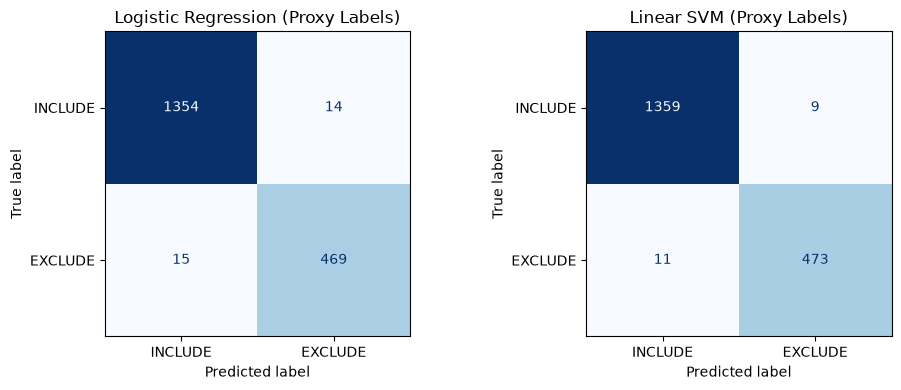

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    predicted = test_predictions[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test_proxy, predicted, labels=[0, 1],
        display_labels=['INCLUDE', 'EXCLUDE'], ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(name + ' (Proxy Labels)')
    print('\n', name, '- proxy classification report')
    print(classification_report(y_test_proxy, predicted,
                                labels=[0, 1], target_names=['INCLUDE', 'EXCLUDE'],
                                zero_division=0))
plt.tight_layout()
plt.savefig(OUTPUT / '05_confusion_matrix_proxy.png', dpi=150)
plt.show()

### KODE 22 — Evaluasi Tambahan dengan Label IT

**Tujuan:** Menghitung metrik sebenarnya hanya pada data test yang punya label IT.  
**Output:** Tabel evaluasi IT atau pesan jika belum tersedia.

In [53]:
verified_test = test_predictions[test_predictions['it_label'].notna()].copy()
verified_results = []
if len(verified_test) > 0:
    y_verified = verified_test['it_label'].astype(int)
    for name in models:
        verified_results.append({
            'Model': name,
            'IT-Labeled Test Rows': len(verified_test),
            'Accuracy (IT)': accuracy_score(y_verified, verified_test[name]),
            'Macro F1 (IT)': f1_score(y_verified, verified_test[name],
                                     average='macro', zero_division=0)
        })
    verified_results = pd.DataFrame(verified_results)
    display(verified_results.round(3))
else:
    verified_results = pd.DataFrame()
    print('No IT-labeled test rows. Independent IT accuracy is unavailable.')

,Model,IT-Labeled Test Rows,Accuracy (IT),Macro F1 (IT)
0,Logistic Regression,38,0.579,0.513
1,Linear SVM,38,0.579,0.513


### KODE 23 — Menganalisis Kesalahan Prediksi

**Tujuan:** Melihat software yang tidak sesuai dengan label kerja.  
**Output:** Contoh kesalahan model dan file CSV.

In [54]:
error_examples = test_predictions[
    test_predictions['Logistic Regression'] != test_predictions['proxy_label']
].copy()
print('Proxy disagreements (Logistic Regression):', len(error_examples))
display(error_examples.head(15))
error_examples.to_csv(OUTPUT / '06_proxy_disagreements.csv', index=False)

Proxy disagreements (Logistic Regression): 29


,software_name,manufacturer,software_category,proxy_label,label_source,it_label,dictionary_rule_id,Logistic Regression,Linear SVM
16,Microsoft Blend for Visual Studio 2015,Microsoft Corporation,,0,DEFAULT_INCLUDE_PROXY,NaN,,1,1
25,PuTTY release 0.70 (64-bit),Simon Tatham,,1,IT_REFERENCE,1.0,,0,0
48,Nitro Pro 7,Nitro PDF Software,application,1,DICTIONARY_RULE,NaN,220,0,1
55,Windows App Runtime DDLM 2.3.1.0-x6,Microsoft Corporation,developer,1,IT_REFERENCE,1.0,,0,0
61,"Adobe Acrobat 9 Pro - English, Français, Deutsch",Adobe Systems,system_component,0,IT_REFERENCE,0.0,226,1,1
90,Catalyst Control Center Next Localization PL,"Advanced Micro Devices, Inc.",system_component,0,IT_REFERENCE,0.0,226,1,1
113,Visual Studio Professional 2022,Microsoft Corporation,application,0,DEFAULT_INCLUDE_PROXY,NaN,,1,1
130,Express Rip CD Ripper Software,NCH Software,,1,IT_REFERENCE,1.0,,0,0
337,Web Components,,application,0,DEFAULT_INCLUDE_PROXY,NaN,,1,0
398,"MEmu????????????,/MEmu{?????????%??ï¿½#???????...",Microvirt Software Technology Co. Ltd.)???????...,,1,DICTIONARY_RULE,NaN,229,0,1


### KODE 24 — Membandingkan Dictionary dengan Label IT

**Tujuan:** Memeriksa konflik antara aturan operasional dan referensi IT.  
**Output:** Tabel konflik yang perlu ditinjau.

In [55]:
manual_rows = catalog[catalog['it_label'].notna()].copy()
conflicts = manual_rows[
    (manual_rows['dictionary_hit']) & (manual_rows['it_label'] == 0)
][['software_name', 'manufacturer', 'dictionary_rule_id', 'it_label']].copy()
print('Dictionary EXCLUDE vs IT INCLUDE conflicts:', len(conflicts))
display(conflicts.head(15))
conflicts.to_csv(OUTPUT / '07_dictionary_it_conflicts.csv', index=False)

Dictionary EXCLUDE vs IT INCLUDE conflicts: 36


,software_name,manufacturer,dictionary_rule_id,it_label
358,"Adobe Acrobat 9 Pro - English, Français, Deutsch",Adobe Systems,226,0.0
361,Adobe Acrobat 8 Professional,Adobe Systems,226,0.0
723,AMD WVR64,"Advanced Micro Devices, Inc.",226,0.0
979,AutoCAD 2026 - English,AUTODESK,226,0.0
1231,Autodesk Navisworks Freedom 2022 - English Lan...,AUTODESK,226,0.0
1236,Autodesk Navisworks Freedom 2023 - 简体中文(Simpli...,AUTODESK,226,0.0
1241,Autodesk Navisworks Freedom 2023 - Module ling...,AUTODESK,226,0.0
1731,Catalyst Control Center Next Localization PL,"Advanced Micro Devices, Inc.",226,0.0
1795,Visual F# 3.1 VS,Microsoft Corporation,226,0.0
2076,CorelDRAW Graphics Suite 2019 - EN (x64),Corel Corporation,226,0.0


## 4.6 Deployment — Prototipe Klasifikasi Software

Deployment berbentuk ekspor rekomendasi **CSV/Excel**, bukan perubahan langsung pada Dictionary GLPI. Model untuk contoh deployment ditentukan di bawah; pemilihan ini bukan klaim bahwa model sudah tervalidasi sepenuhnya oleh IT.

### KODE 25 — Memilih Model untuk Prototipe

**Tujuan:** Menentukan model yang digunakan pada contoh deployment.  
**Output:** Model aktif untuk prediksi katalog.

In [56]:
selected_name = 'Logistic Regression'  # Change after independent IT evaluation.
selected_model = models[selected_name]
print('Selected model:', selected_name)

Selected model: Logistic Regression


### KODE 26 — Memprediksi Seluruh 9.256 Software

**Tujuan:** Memberi rekomendasi kepada seluruh katalog software.  
**Output:** Tabel rekomendasi dengan sumber label.

In [57]:
X_all = vectorizer.transform(catalog['text'])
recommendations = catalog[['software_name', 'manufacturer', 'software_category',
                            'dictionary_rule_id', 'label_source', 'it_label']].copy()
recommendations['predicted_id'] = selected_model.predict(X_all)
recommendations['recommendation'] = recommendations['predicted_id'].map({
    0: 'INCLUDE', 1: 'EXCLUDE_CANDIDATE'
})
recommendations['data_split'] = np.where(
    catalog['name_key'].isin(test_data['name_key']), 'TEST', 'TRAIN'
)
print('Recommendations:', len(recommendations))
display(recommendations['recommendation'].value_counts().to_frame('total'))

Recommendations: 9256


,total
recommendation,
INCLUDE,6858
EXCLUDE_CANDIDATE,2398


### KODE 27 — Menyimpan Laporan CSV dan Excel

**Tujuan:** Mengekspor hasil model dan evaluasi untuk BAB IV.  
**Output:** File laporan di folder hasil_bab4.

In [ ]:
recommendations.to_csv(OUTPUT / '08_all_software_recommendations.csv', index=False)
with pd.ExcelWriter(OUTPUT / '09_BAB_IV_Report.xlsx', engine='openpyxl') as writer:
    recommendations.to_excel(writer, sheet_name='Recommendations', index=False)
    test_predictions.to_excel(writer, sheet_name='Test_1852', index=False)
    proxy_results.to_excel(writer, sheet_name='Proxy_Evaluation', index=False)
    if not verified_results.empty:
        verified_results.to_excel(writer, sheet_name='IT_Evaluation', index=False)
    conflicts.to_excel(writer, sheet_name='Dictionary_Conflicts', index=False)
print('Excel report saved:', OUTPUT / '09_BAB_IV_Report.xlsx')

### KODE 28 — Menyimpan Model dan Contoh Prediksi Baru

**Tujuan:** Menyimpan model agar dapat digunakan ulang di VS Code.  
**Output:** File joblib dan hasil prediksi contoh.

In [ ]:
joblib.dump({'vectorizer': vectorizer, 'model': selected_model},
            OUTPUT / '10_software_classifier.joblib')

example = pd.DataFrame({
    'software_name': ['Microsoft Office 2021', 'Windows Language Pack'],
    'manufacturer': ['Microsoft', 'Microsoft'],
    'software_category': ['application', 'system_component']
})
example['text'] = (example['software_name'] + ' ' + example['manufacturer'] + ' ' +
                   example['software_category']).str.strip()
example['prediction'] = selected_model.predict(vectorizer.transform(example['text']))
example['recommendation'] = example['prediction'].map({0: 'INCLUDE', 1: 'EXCLUDE_CANDIDATE'})
display(example[['software_name', 'recommendation']])
print('Model saved to:', OUTPUT / '10_software_classifier.joblib')

---
### Catatan untuk penulisan BAB IV

- **Jumlah train-test:** seluruh **9.256 software bersih** di-split menjadi **7.404 training** dan **1.852 testing**.
- **KODE 20–21:** angka dari 1.852 data mengukur **agreement terhadap proxy label**, **bukan accuracy berstandar IT**.
- **KODE 22:** metrik berstandar IT hanya dihitung untuk software test yang memang mempunyai label referensi.
- **KODE 12:** jika file `IT_Validation_1000.xlsx` diberikan nanti, notebook otomatis memakainya saat dijalankan ulang. Jika nama file berbeda, ubah daftar `label_candidates`.
- **KODE 13:** software yang tidak cocok dengan Dictionary sementara dianggap INCLUDE **hanya untuk membuat label kerja eksperimen**, bukan kesimpulan atau persetujuan IT.
- **KODE 26:** seluruh 9.256 mendapat rekomendasi; output `TRAIN` merupakan prediksi *in-sample*, output `TEST` merupakan prediksi *held-out*.
- **Penting:** karena label proxy dibuat dari aturan yang juga diketahui model, hasil proxy tinggi hanya membuktikan model mendekati aturan tersebut. Untuk klaim performa sebenarnya, diperlukan label IT independen; idealnya sampel final baru yang tidak digunakan saat pengembangan.
- **Konsistensi naskah:** jika BAB I–III sebelumnya menyebut *clustering*, harus disesuaikan dengan metode klasifikasi sebelum finalisasi skripsi.